# 02 · Exploratory analysis

Fourteen seasons of MotoGP: who won, how much the grid matters, how often riders crash,
what the Saturday sprint tells you about Sunday, and how rain changes the picture.

In [1]:
import warnings

import matplotlib.pyplot as plt
import pandas as pd
from scipy.stats import ConstantInputWarning

from motogp_analytics import plots

# One 2013 race has no qualifying data, so its reconstructed grid is constant and its
# grid-vs-finish correlation is undefined (NaN, skipped in averages).
warnings.filterwarnings("ignore", category=ConstantInputWarning)
from motogp_analytics.config import DATA_PROCESSED
from motogp_analytics.data import load_tables
from motogp_analytics.features import build_features

plots.apply_style()
t = load_tables()
df = build_features(t["events"], t["sessions"], t["results"])
df.to_parquet(DATA_PROCESSED / "features.parquet", index=False)
print(f"{len(df):,} rider-race rows, {df['race_id'].nunique()} races, {df['rider_id'].nunique()} riders")

5,860 rider-race rows, 260 races, 96 riders


## 1. Manufacturer eras

Honda (Márquez) and Yamaha (Lorenzo, Rossi, Quartararo) shared the 2010s. Ducati won 12 of 20
races in 2022 and then 17, 19 and 17 over the next three seasons, with up to eight bikes on the
grid. 2026 broke the pattern: **Aprilia matched Ducati win for win.**

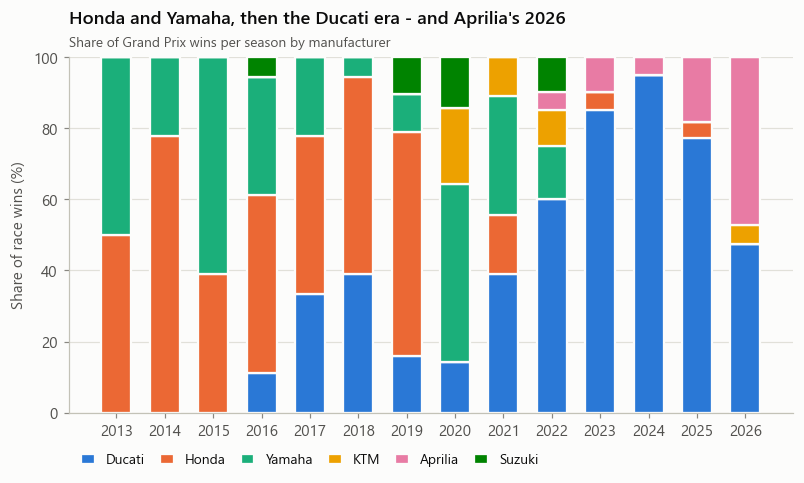

In [2]:
fig = plots.manufacturer_share(df, "win")
plots.save(fig, "manufacturer_wins")
plt.show()

In [3]:
wins = df[df["win"] == 1].pivot_table(index="season", columns="manufacturer", values="win",
                                      aggfunc="sum", fill_value=0)
wins

manufacturer,Aprilia,Ducati,Honda,KTM,Suzuki,Yamaha
season,,,,,,
2013,0,0,9,0,0,9
2014,0,0,14,0,0,4
2015,0,0,7,0,0,11
2016,0,2,9,0,1,6
2017,0,6,8,0,0,4
2018,0,7,10,0,0,1
2019,0,3,12,0,2,2
2020,0,2,0,3,2,7
2021,0,7,3,2,0,6


## 2. How much does the grid matter?

Much less than in Formula 1 (where P1 reaches the podium about 80 % of the time). Racing on two
wheels has more overtaking, more crashes and a tighter field.

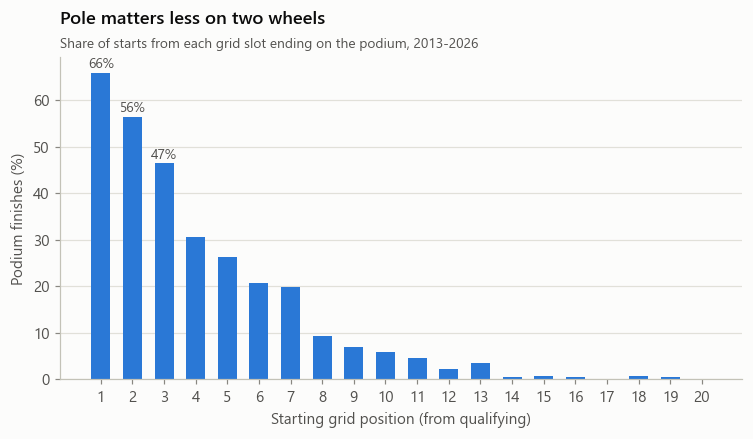

From grid P1: win 38%, podium 66%


In [4]:
fig = plots.podium_rate_by_grid(df)
plots.save(fig, "podium_rate_by_grid")
plt.show()
front = df[df["grid"] == 1]
print(f"From grid P1: win {front['win'].mean():.0%}, podium {front['podium'].mean():.0%}")

In [5]:
per_race_rho = df.groupby("race_id").apply(
    lambda r: r["grid"].corr(r["finish_position"], method="spearman"), include_groups=False)
print(f"Average grid-vs-finish rank correlation per race: {per_race_rho.mean():.2f}")

Average grid-vs-finish rank correlation per race: 0.54


## 3. Crashes and retirements

Roughly one start in five ends without a classified finish. Rates differ by manufacturer, and
riders starting further back crash more, because the midfield is where the first-lap
incidents happen.

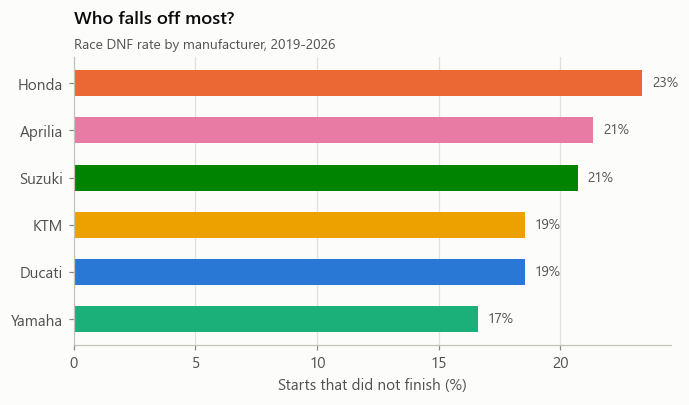

In [6]:
fig = plots.dnf_by_manufacturer(df, since=2019)
plots.save(fig, "dnf_by_manufacturer")
plt.show()

In [7]:
dnf_grid = df.groupby(pd.cut(df["grid"], [0, 3, 6, 12, 18, 30],
                             labels=["1-3", "4-6", "7-12", "13-18", "19+"]),
                      observed=True)["dnf"].mean()
dnf_grid.to_frame("DNF rate").style.format("{:.1%}")

,DNF rate
grid,
1-3,15.5%
4-6,18.0%
7-12,19.4%
13-18,20.4%
19+,21.4%


## 4. Wet vs. dry races

A race counts as wet when the track was declared wet (or wet-dry) at the start.

In [8]:
race_level = df.groupby("race_id").agg(
    wet=("wet", "first"),
    dnf_rate=("dnf", "mean"),
    winner_grid=("grid", lambda g: g[df.loc[g.index, "win"] == 1].min()),
)
race_level["grid_finish_rho"] = per_race_rho
summary = race_level.groupby("wet").agg(
    races=("dnf_rate", "size"),
    dnf_rate=("dnf_rate", "mean"),
    grid_finish_rho=("grid_finish_rho", "mean"),
    winner_from_front_row=("winner_grid", lambda g: (g <= 3).mean()),
)
summary.index = summary.index.map({0: "Dry", 1: "Wet"})
summary.style.format({"dnf_rate": "{:.1%}", "grid_finish_rho": "{:.2f}",
                      "winner_from_front_row": "{:.0%}"})

,races,dnf_rate,grid_finish_rho,winner_from_front_row
wet,,,,
Dry,237,19.4%,0.55,73%
Wet,23,18.7%,0.38,48%


Wet races are **less predictable from the grid** (lower rank correlation, fewer winners
from the front row). They do **not** produce more retirements, though: riders back off in
the rain.

## 5. Sprint → Sunday

Since 2023 every weekend has a half-distance Saturday sprint. How often does its winner go on
to win the Grand Prix?

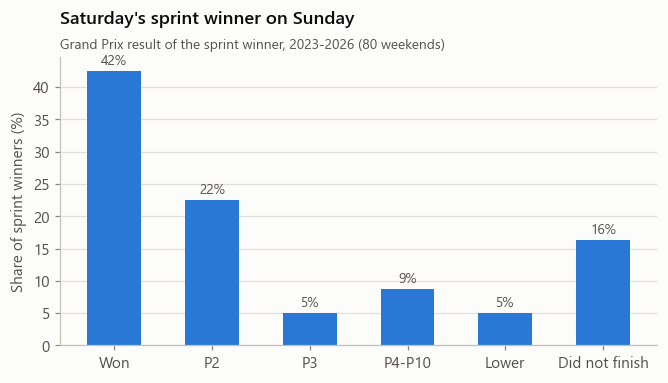

Rank correlation with the Sunday result, same weekends:
  grid only          0.50
  sprint only        0.50
  average of the two 0.52


In [9]:
fig = plots.sprint_winner_sunday(df)
plots.save(fig, "sprint_winner_sunday")
plt.show()
spr = df.dropna(subset=["sprint_position"])
rho = spr.groupby("race_id").apply(
    lambda r: r["sprint_position"].corr(r["finish_position"], method="spearman"),
    include_groups=False)
both = spr.groupby("race_id").apply(
    lambda r: r[["grid", "sprint_position"]].mean(axis=1).corr(r["finish_position"],
                                                               method="spearman"),
    include_groups=False)
print(f"Rank correlation with the Sunday result, same weekends:\n"
      f"  grid only          {per_race_rho[rho.index].mean():.2f}\n"
      f"  sprint only        {rho.mean():.2f}\n"
      f"  average of the two {both.mean():.2f}")

Taken alone, the sprint result is **no better a guide to Sunday than the grid**. Both have
about the same rank correlation with the race result. Crashes in either race dilute both
signals. The sprint winner still wins the Grand Prix about four times in ten, and averaging
the two orders is slightly better than either alone (0.52 vs 0.50). That is why both are
features in the models.

## 6. Title fights

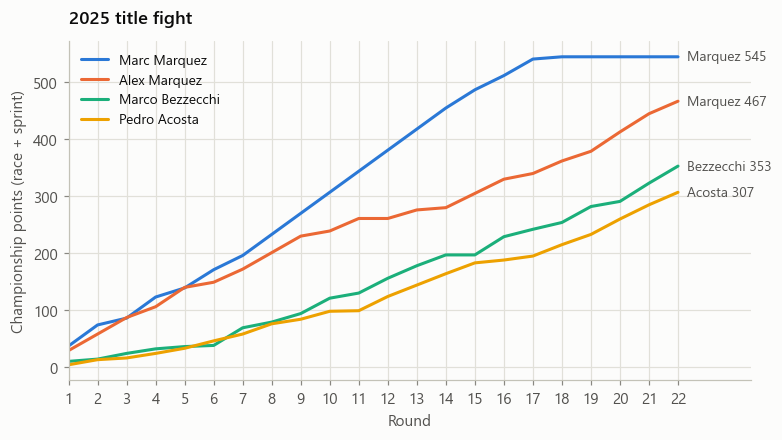

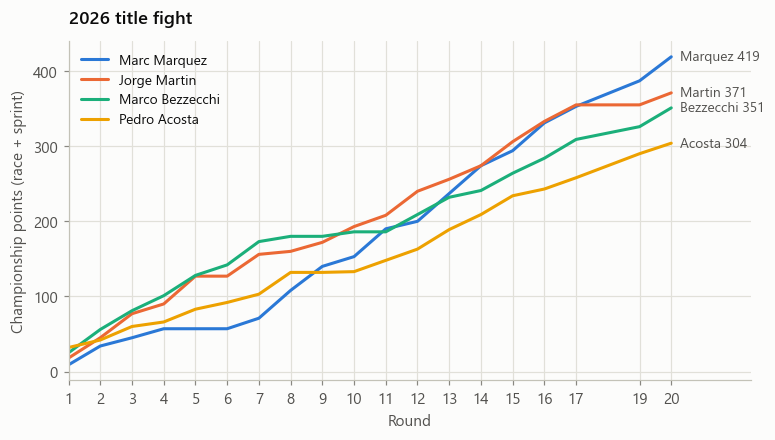

In [10]:
latest = int(df["season"].max())
for season in (latest - 1, latest):
    fig = plots.championship_progression(df, season)
    plots.save(fig, f"championship_{season}")
    plt.show()